# Train on English, evaluate on Kazakh

The 300 translated conversations exist in both languages with identical structure and
identical entities. So the gap between a model's score on the English 300 and the
Kazakh 300 is the cost of the language change and **nothing else** — same
conversations, same labels, one variable. That is the experiment this dataset was
built to make possible.

It also tests the claim notebook 02 makes about feature groups: that `struct_` and
`entity_` survive translation while `surface_` and `lex_` do not. If that is right, a
model restricted to the invariant groups should lose almost nothing across the
language boundary, and a character n-gram model should fall off a cliff.

The experiment is `scripts/run_crosslingual.py`, imported here rather than
reimplemented.

Prerequisites:

```
python scripts/build_features.py   --merged data/merged --out data/features
python scripts/make_group_split.py --merged data/merged --out data/splits
python scripts/encode_corpus.py    --merged data/merged --out data/embeddings
python scripts/run_crosslingual.py --features data/features --merged data/merged \
    --out data/experiments --embeddings data/embeddings
```

In [1]:
import pathlib
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
            if (p / "scripts").is_dir())
sys.path.insert(0, str(ROOT / "scripts"))

import build_features as bf
import encode_corpus
import run_crosslingual as rx

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#dcdcd8"


def bare_axes(ax, xlabel=None):
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
    ax.xaxis.grid(True, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=MUTED, length=0)
    if xlabel:
        ax.set_xlabel(xlabel, color=MUTED, fontsize=9)
    return ax


features, merged = rx.load(ROOT / "data" / "features", ROOT / "data" / "merged")
print(f"{len(features):,} rows")

37,721 rows


## 1. Two contaminations had to be removed first

Neither was obvious, and the first version of this experiment reported numbers that
were badly wrong because of them.

**The split rule puts English twins in training.** Each Kazakh row inherits its
source's split — correct for the merged dataset, wrong here. 233 of the 300 English
twins sit in the training split, so a model trained on all English rows would have
read the English version of most conversations it is then tested on in Kazakh. That is
not zero-shot; it is memorisation with a translation step.

**Restylings are worse.** Holding out the 300 source rows is not enough. The augmented
pool rewrites one conversation in up to 76 voices, and 3,473 training rows are
restylings of 273 of the 300 — a median of 12 each. With those left in, a character
n-gram model scored **0.973** on the "held-out" English by recognising text it had
already read in another register.

So the whole conversation family goes out together.

In [2]:
train, english_300, kazakh = rx.split_sets(features, merged)

source_ids = set(kazakh.translated_from)
naive = features[(features.language == "en") & (features.split == "train")
                 & (~features.id.isin(source_ids))]

print(f"English rows in the training split   "
      f"{((features.language=='en') & (features.split=='train')).sum():>7,}")
print(f"  minus the 300 source rows          {len(naive):>7,}")
print(f"  minus every restyling of them      {len(train):>7,}   <- what we train on")
print(f"\nevaluation: {len(english_300)} EN and {len(kazakh)} KK -- the same conversations")

English rows in the training split    16,141
  minus the 300 source rows           15,908
  minus every restyling of them       12,435   <- what we train on

evaluation: 300 EN and 300 KK -- the same conversations


## 2. Does a multilingual encoder actually align the two languages?

Character n-grams cannot cross a script boundary by construction: a Cyrillic string
shares almost no 3-grams with its Latin source. The obvious repair is an encoder
trained to put a sentence and its translation in the same place.

Before trusting one, check that it does. The 300 pairs are a ready-made test: encode
both languages, and see whether each English conversation's nearest Kazakh neighbour
is its own translation.

In [3]:
MODELS = ["intfloat/multilingual-e5-small", "sentence-transformers/LaBSE"]

for model_name in MODELS:
    cached = encode_corpus.load_cached(ROOT / "data" / "embeddings", model_name)
    if cached is None:
        print(f"{model_name}: not encoded yet")
        continue
    vectors = lambda ids: np.vstack(cached.loc[ids].to_numpy())
    kk_vectors, en_vectors = vectors(kazakh.id), vectors(kazakh.translated_from)
    similarity = en_vectors @ kk_vectors.T
    paired = np.diag(similarity)
    first = (similarity > paired[:, None]).sum(1) == 0

    sample = vectors(train.id.sample(2000, random_state=0))
    spread = sample @ sample.T
    background = spread[~np.eye(len(spread), dtype=bool)].mean()

    print(f"{model_name.split('/')[-1]}")
    print(f"   translation retrieved first      {first.sum()}/{len(first)}")
    print(f"   cosine, a pair                   {paired.mean():.3f}")
    print(f"   cosine, two random conversations {background:.3f}   <- how spread out the space is")
    print()

multilingual-e5-small
   translation retrieved first      265/300
   cosine, a pair                   0.916
   cosine, two random conversations 0.879   <- how spread out the space is



LaBSE
   translation retrieved first      286/300
   cosine, a pair                   0.898
   cosine, two random conversations 0.532   <- how spread out the space is



/var/folders/yk/q36_hdnx24sfgw0x0h40pyw80000gn/T/ipykernel_59855/1062218429.py:10: RuntimeWarning: divide by zero encountered in matmul
  similarity = en_vectors @ kk_vectors.T
/var/folders/yk/q36_hdnx24sfgw0x0h40pyw80000gn/T/ipykernel_59855/1062218429.py:10: RuntimeWarning: overflow encountered in matmul
  similarity = en_vectors @ kk_vectors.T
/var/folders/yk/q36_hdnx24sfgw0x0h40pyw80000gn/T/ipykernel_59855/1062218429.py:10: RuntimeWarning: invalid value encountered in matmul
  similarity = en_vectors @ kk_vectors.T
/var/folders/yk/q36_hdnx24sfgw0x0h40pyw80000gn/T/ipykernel_59855/1062218429.py:15: RuntimeWarning: divide by zero encountered in matmul
  spread = sample @ sample.T
/var/folders/yk/q36_hdnx24sfgw0x0h40pyw80000gn/T/ipykernel_59855/1062218429.py:15: RuntimeWarning: overflow encountered in matmul
  spread = sample @ sample.T
/var/folders/yk/q36_hdnx24sfgw0x0h40pyw80000gn/T/ipykernel_59855/1062218429.py:15: RuntimeWarning: invalid value encountered in matmul
  spread = sample

Both encoders align the languages well — a conversation's own translation is its
nearest neighbour for 265/300 and 286/300 respectively. That is exactly the capability
char n-grams lack, so the expectation going in was that the encoders would win.

**The third number is the one to watch.** It asks how spread out the space is, and the
two models differ sharply: under e5-small two *unrelated* conversations sit at cosine
0.85, under LaBSE at 0.54. e5-small compresses this entire corpus into a narrow cone —
every conversation here shares a format, a register and a topic, and a small
general-purpose encoder sees them as nearly the same thing. LaBSE does not have that
problem.

So if narrow spread were the whole story, LaBSE should be much the better classifier.
Section 4 shows it is barely better, which is informative in itself.

## 3. Results

In [4]:
results = pd.read_csv(ROOT / "data" / "experiments" / "crosslingual_results.csv").set_index("model")
results.round(3)

,EN-300,KK-300,gap
model,,,
majority class,0.167,0.167,0.000
hand features (all 54),0.563,0.539,0.024
"hand features (struct+entity, 25)",0.343,0.346,-0.002
char n-gram TF-IDF (3-5),0.736,0.491,0.245
word TF-IDF (1-2),0.690,0.416,0.274
multilingual encoder (multilingual-e5-small),0.522,0.462,0.059
encoder + hand features (multilingual-e5-small),0.528,0.495,0.034
multilingual encoder (LaBSE),0.534,0.484,0.050
encoder + hand features (LaBSE),0.586,0.492,0.093


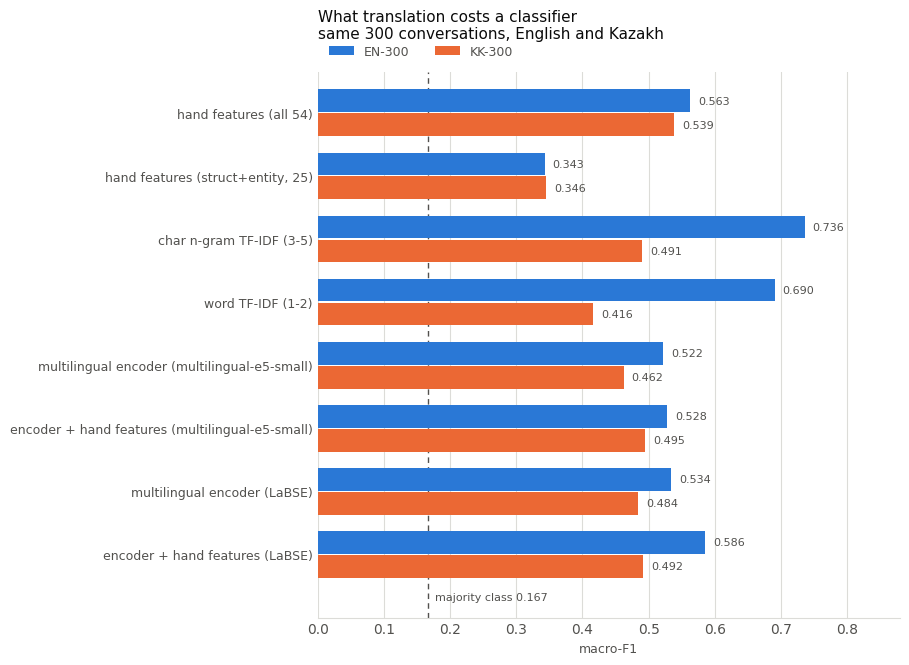

In [5]:
order = results.drop(index="majority class").index[::-1]
y = np.arange(len(order))
height = 0.36

fig, ax = plt.subplots(figsize=(9.2, 0.62 * len(order) + 1.8))
ax.barh(y + height / 2 + 0.01, results.loc[order, "EN-300"], height=height,
        color=BLUE, label="EN-300")
ax.barh(y - height / 2 - 0.01, results.loc[order, "KK-300"], height=height,
        color=ORANGE, label="KK-300")

for i, name in enumerate(order):
    ax.text(results.loc[name, "EN-300"] + 0.012, i + height / 2 + 0.01,
            f"{results.loc[name, 'EN-300']:.3f}", va="center", fontsize=8, color=MUTED)
    ax.text(results.loc[name, "KK-300"] + 0.012, i - height / 2 - 0.01,
            f"{results.loc[name, 'KK-300']:.3f}", va="center", fontsize=8, color=MUTED)

baseline = results.loc["majority class", "EN-300"]
ax.axvline(baseline, color=MUTED, linewidth=1, linestyle=(0, (4, 3)), zorder=0)
ax.text(baseline + 0.01, -0.68, f"majority class {baseline:.3f}",
        fontsize=8, color=MUTED, va="center")

ax.set_yticks(y)
ax.set_yticklabels(order, fontsize=9)
ax.set_title("What translation costs a classifier\nsame 300 conversations, English and Kazakh",
             loc="left", color=INK, fontsize=11, pad=24)
bare_axes(ax, "macro-F1")
ax.set_xlim(0, 0.88)
ax.set_ylim(-1.0, len(order) - 0.35)
ax.legend(frameon=False, ncol=2, labelcolor=MUTED, fontsize=9,
          loc="lower left", bbox_to_anchor=(0, 1.005))
plt.tight_layout()
plt.show()

## 4. What it says

**The feature grouping from notebook 02 holds up.** That was a prediction made before
any model was trained, and it survived: the `struct_`+`entity_` model has a gap of
−0.002, while the lexical models lose a quarter of their score.

**The multilingual encoders did not win, and that was the stated expectation going
in.** The plan written at the end of the previous round was that an encoder would beat
char n-grams, because char n-grams cannot cross a script boundary. That prediction was
wrong, and both encoders agree it was wrong:

| | EN-300 | KK-300 |
|---|---:|---:|
| hand features (54) | 0.563 | **0.539** |
| LaBSE | 0.534 | 0.484 |
| LaBSE + hand features | 0.586 | 0.492 |
| e5-small | 0.522 | 0.462 |

They *do* transfer far better — gaps of 0.05–0.09 against 0.245–0.274 for the lexical
models — but their absolute scores are low enough that better transfer does not buy a
better Kazakh model than 54 hand-built numbers.

**The tempting explanation is only half right.** e5-small's space is pathologically
narrow (0.85 between unrelated conversations), which does explain *its* weakness. But
LaBSE's space is healthy at 0.54 and it gains barely two points. Narrow spread is a
real defect in the smaller model and not the reason the approach falls short.

The better reading: a frozen sentence embedding is a summary of *what a conversation is
about*, and every conversation in this corpus is about the same thing — a user asking
an assistant for something. What separates SCAM from LEGITIMATE is a turn of phrase, a
request slipped into a system prompt, who speaks last. Mean-pooling 512 tokens into one
vector throws exactly that away.

**This is a negative result about one method, not about transformers.** A frozen
encoder with a linear probe is the cheap form; fine-tuning XLM-R end-to-end is the
version with a real chance and needs a GPU we do not have here. The honest claim is
that **frozen multilingual sentence embeddings do not help on this task** — worth
knowing before spending a week on them.

**There is a real trade between accuracy and transferability.** Char n-grams are the
strongest English model and among the weakest Kazakh ones. The hand features are worse
in English and better in Kazakh. On the language this project is about, the
interpretable features win.

**Perfect transfer of a weak signal is not a solution.** The invariant-only model
transfers flawlessly at 0.343 against a 0.167 baseline.

In [6]:
print((ROOT / "data" / "experiments" / "crosslingual_report.md").read_text().split("## Per-class")[1])

 on Kazakh, best model (hand features (all 54))

```
              precision    recall  f1-score   support

  LEGITIMATE       0.67      0.78      0.72       100
        SCAM       0.44      0.24      0.31       100
  SUSPICIOUS       0.52      0.67      0.58       100

    accuracy                           0.56       300
   macro avg       0.54      0.56      0.54       300
weighted avg       0.54      0.56      0.54       300

```



That per-class table is the number that matters most in the whole project. On Kazakh
the best model finds roughly **one scam in four**. A system shipped on this would miss
most of what it exists to catch.

## 5. How much of this can we trust?

300 conversations per evaluation set, 100 per class.

In [7]:
for n, score in [(300, 0.54), (100, 0.54)]:
    half = 1.96 * np.sqrt(score * (1 - score) / n)
    print(f"n={n:<4} score {score:.2f}  ->  95% CI +/- {100*half:.1f} points")

best_kk = results.drop(index="majority class")["KK-300"].sort_values(ascending=False)
print(f"\ntop two on Kazakh: {best_kk.index[0]} {best_kk.iloc[0]:.3f}, "
      f"{best_kk.index[1]} {best_kk.iloc[1]:.3f}")
print(f"difference {best_kk.iloc[0] - best_kk.iloc[1]:.3f} -- inside the interval, so not")
print("a difference this evaluation set can resolve. The large gaps are real; the")
print("small ones are not. That is the argument for more Kazakh data, stated as a")
print("measurement rather than a wish.")

n=300  score 0.54  ->  95% CI +/- 5.6 points
n=100  score 0.54  ->  95% CI +/- 9.8 points

top two on Kazakh: hand features (all 54) 0.539, encoder + hand features (multilingual-e5-small) 0.495
difference 0.044 -- inside the interval, so not
a difference this evaluation set can resolve. The large gaps are real; the
small ones are not. That is the argument for more Kazakh data, stated as a
measurement rather than a wish.


## 6. What this changes

**The Kazakh slice earned its place.** It detected a 0.245 transfer gap and a failed
intervention, neither of which any amount of English evaluation would have revealed.

**For the corpus.** Finding the restyling leak means every score previously measured
against ScamBench's own splits is inflated, ours included. Notebook 02 now reports
both: 0.783 on the original split, **0.650** on the grouped one.

**What to try next**, revised by these results rather than by expectation:

1. **Fine-tune, do not freeze.** Both encoders align the languages; what they lack is
   discrimination on this domain, and a linear probe on a frozen vector cannot add it.
   Fine-tuning XLM-R on the English training set is the version of this experiment with
   a real chance. It needs a GPU.
2. **Translate-train.** Machine-translate English training data into Kazakh and train
   on the mixture, keeping the 300 human translations as the gold test set. Cheap, and
   it attacks the actual problem — the model has never seen Kazakh.
3. **More Kazakh** — `scripts/select_expanded.py` shows 326 more per class available
   with no external data. Worth doing once there is a comparison worth resolving;
   right now the top two models are tied inside the interval.